In [127]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ratings = pd.read_csv("../data/raw/ratings.csv")
movies = pd.read_csv("../data/raw/movies.csv")
tags = pd.read_csv("../data/raw/tags.csv")
links = pd.read_csv("../data/raw/links.csv")

print(ratings.head())
print(movies.head())
print(tags.head())
print(links.head())

   userId  movieId  rating  timestamp
0       1        1     4.0  964982703
1       1        3     4.0  964981247
2       1        6     4.0  964982224
3       1       47     5.0  964983815
4       1       50     5.0  964982931
   movieId                               title  \
0        1                    Toy Story (1995)   
1        2                      Jumanji (1995)   
2        3             Grumpier Old Men (1995)   
3        4            Waiting to Exhale (1995)   
4        5  Father of the Bride Part II (1995)   

                                        genres  
0  Adventure|Animation|Children|Comedy|Fantasy  
1                   Adventure|Children|Fantasy  
2                               Comedy|Romance  
3                         Comedy|Drama|Romance  
4                                       Comedy  
   userId  movieId              tag   timestamp
0       2    60756            funny  1445714994
1       2    60756  Highly quotable  1445714996
2       2    60756     will ferre

In [128]:
# Check for missing values in each dataset


print("RATINGS")
print(ratings.isnull().sum())

print("\nMOVIES")
print(movies.isnull().sum())

print("\nTAGS")
print(tags.isnull().sum())

print("\nLINKS")
print(links.isnull().sum())

RATINGS
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

MOVIES
movieId    0
title      0
genres     0
dtype: int64

TAGS
userId       0
movieId      0
tag          0
timestamp    0
dtype: int64

LINKS
movieId    0
imdbId     0
tmdbId     8
dtype: int64


In [129]:
# checking for duplicates in each dataset

print("Duplicate ratings:", ratings.duplicated().sum())
print("Duplicate movies:", movies.duplicated().sum())
print("Duplicate tags:", tags.duplicated().sum())
print("Duplicate links:", links.duplicated().sum())

Duplicate ratings: 0
Duplicate movies: 0
Duplicate tags: 0
Duplicate links: 0


In [130]:
print(ratings["rating"].describe())

print(
    ratings[
        (ratings["rating"] < 0.5) |
        (ratings["rating"] > 5.0) |
        ((ratings["rating"] * 2) % 1 != 0)
    ]
)

count    100836.000000
mean          3.501557
std           1.042529
min           0.500000
25%           3.000000
50%           3.500000
75%           4.000000
max           5.000000
Name: rating, dtype: float64
Empty DataFrame
Columns: [userId, movieId, rating, timestamp]
Index: []


In [131]:
# checking for unknown movie IDs in the ratings dataset

rating_movie_ids = set(ratings["movieId"])
movie_ids = set(movies["movieId"])

unknown_movies = rating_movie_ids - movie_ids

print("Unknown movie IDs:", len(unknown_movies))
print(unknown_movies)

Unknown movie IDs: 0
set()


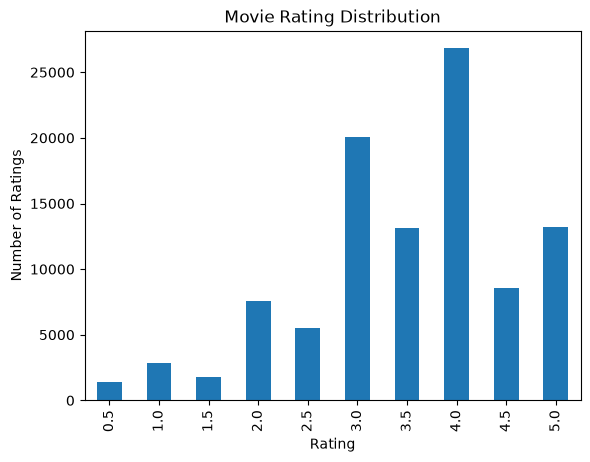

In [132]:
import matplotlib.pyplot as plt

ratings["rating"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Movie Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.show()

In [133]:
# Dataset Summary

print("Total ratings:", len(ratings))
print("Unique users:", ratings["userId"].nunique())
print("Unique movies:", movies["movieId"].nunique())
print("Unique tagged movies:", tags["movieId"].nunique())
print("Total tags:", len(tags))

Total ratings: 100836
Unique users: 610
Unique movies: 9742
Unique tagged movies: 1572
Total tags: 3683


In [134]:
# additional statistics about the ratings dataset

print(ratings["rating"].describe())

print("\nAverage rating:", ratings["rating"].mean())
print("Median rating:", ratings["rating"].median())

count    100836.000000
mean          3.501557
std           1.042529
min           0.500000
25%           3.000000
50%           3.500000
75%           4.000000
max           5.000000
Name: rating, dtype: float64

Average rating: 3.501556983616962
Median rating: 3.5


In [135]:
# extract the year from the movie title and create a new column for it

movies["year"] = movies["title"].str.extract(r"\((\d{4})\)")

movies["year"] = pd.to_numeric(
    movies["year"],
    errors="coerce"
)
movies

,movieId,title,genres,year
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995.0
1,2,Jumanji (1995),Adventure|Children|Fantasy,1995.0
2,3,Grumpier Old Men (1995),Comedy|Romance,1995.0
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,1995.0
4,5,Father of the Bride Part II (1995),Comedy,1995.0
...,...,...,...,...
9737,193581,Black Butler: Book of the Atlantic (2017),Action|Animation|Comedy|Fantasy,2017.0
9738,193583,No Game No Life: Zero (2017),Animation|Comedy|Fantasy,2017.0
9739,193585,Flint (2017),Drama,2017.0
9740,193587,Bungo Stray Dogs: Dead Apple (2018),Action|Animation,2018.0


In [136]:
 # analyze the distribution of movie genres

from collections import Counter

genre_counts = Counter(
    genre
    for genre_list in movies["genres"].str.split("|")
    for genre in genre_list
)

genre_counts = pd.Series(genre_counts).sort_values(
    ascending=False
)

print(genre_counts)

Drama                 4361
Comedy                3756
Thriller              1894
Action                1828
Romance               1596
Adventure             1263
Crime                 1199
Sci-Fi                 980
Horror                 978
Fantasy                779
Children               664
Animation              611
Mystery                573
Documentary            440
War                    382
Musical                334
Western                167
IMAX                   158
Film-Noir               87
(no genres listed)      34
dtype: int64


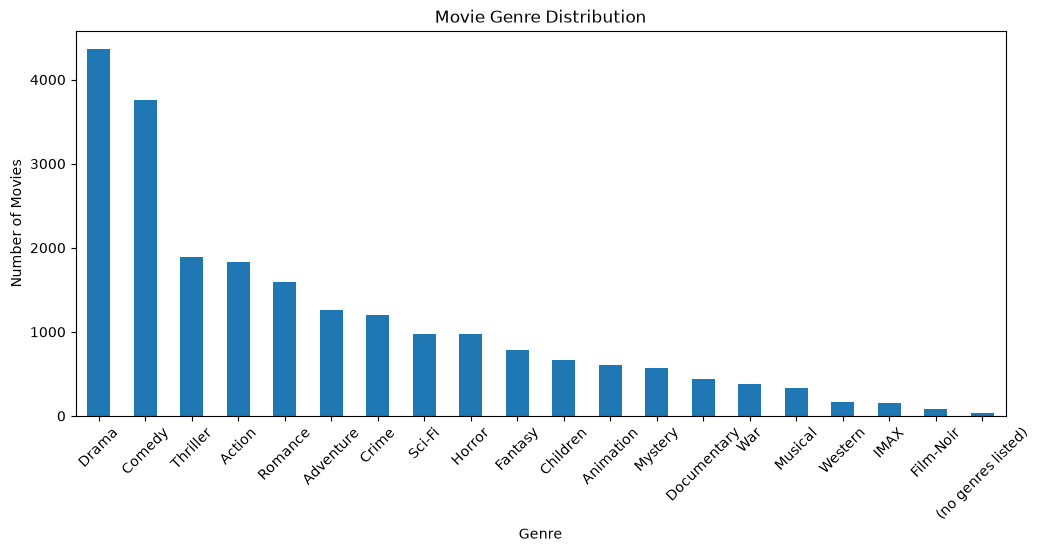

In [137]:
genre_counts.plot(kind="bar", figsize=(12, 5))

plt.title("Movie Genre Distribution")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)
plt.show()

In [138]:
# normalize the tags by converting them to lowercase and stripping whitespace

tags["tag"] = (
    tags["tag"]
    .str.lower()
    .str.strip()
)

In [139]:
# remove rows with missing or empty tags
tags = tags[tags["tag"].notna()]

tags = tags[tags["tag"] != ""]

In [140]:
# remove duplicate tags for the same user and movie
tags = tags.drop_duplicates(
    subset=["userId", "movieId", "tag"]
)

In [141]:
ratings.to_csv(
    "../data/processed/clean_ratings.csv",
    index=False
)

movies.to_csv(
    "../data/processed/clean_movies.csv",
    index=False
)

tags.to_csv(
    "../data/processed/clean_tags.csv",
    index=False
)

links.to_csv(
    "../data/processed/clean_links.csv",
    index=False
)